total, the loop for ran for 2Million times

In [51]:
import numpy as np
import matplotlib.pyplot as plt
from math import e
from math import log

In [2]:
hours_studied = [1.0, 2.0, 3.0, 4.0, 5.0, 5.5, 6.0, 6.5, 7.0, 8.0, 8.5, 9.0, 2.5, 4.5, 7.5]
hours_slept   = [7.0, 6.5, 6.0, 5.5, 7.0, 6.0, 6.5, 5.0, 6.0, 5.5, 7.0, 6.0, 8.0, 4.5, 6.5]
result        = [0,   0,   0,   0,   1,   0,   1,   1,   0,   1,   1,   1,   0,   0,   1]

In [3]:
m = [0, 0]
c = 0
total = len(result)
learningRate = 0.001
costs = list()

In [4]:
def sigmoid(x1, x2):
    y = m[0]*x1 + m[1]*x2 + c
    value = 1 / (1 + e**(-y))

    return value

In [39]:
for i in range(500000):
    dm1 = sum( (sigmoid(x1, x2) - y) * x1 for x1, x2, y in zip(hours_studied, hours_slept, result) ) / total
    dm2 = sum( (sigmoid(x1, x2) - y) * x2 for x1, x2, y in zip(hours_studied, hours_slept, result) ) / total
    dc =  sum( (sigmoid(x1, x2) - y) for x1, x2, y in zip(hours_studied, hours_slept, result) ) / total

    m[0] = m[0] - learningRate * dm1
    m[1] = m[1] - learningRate * dm2
    c = c - learningRate * dc

    if i%5000 == 0:
        cost = sum(-y * log(sigmoid(x1, x2)) - (1 - y) * log(1 - sigmoid(x1, x2)) for y, x1, x2 in zip(result, hours_studied, hours_slept)) / total
        costs.append(cost)

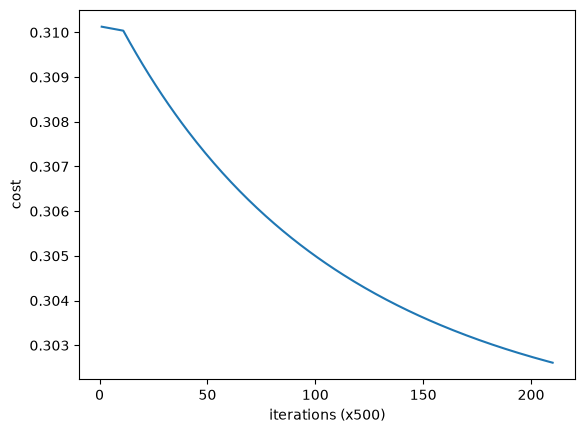

In [49]:
iterations = [i for i in range(1, len(costs) +1)]
plt.plot(iterations, costs)
plt.xlabel("iterations (x500)")
plt.ylabel("cost")
plt.show()

In [ ]:
print(costs[::-1])

print(sigmoid(2, 6))
print(m)

[1.2566203202606665, 0.8505002728785438]


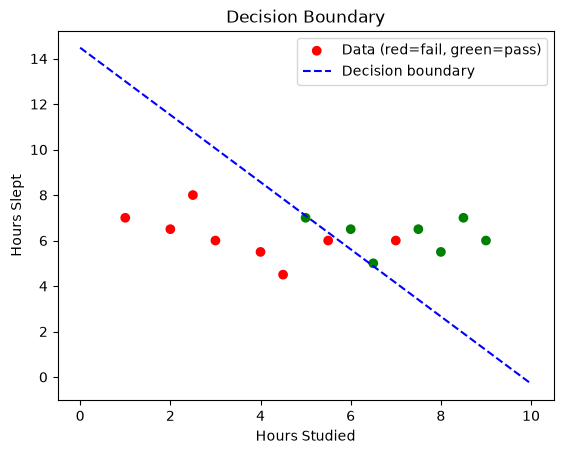

In [45]:
# Scatter actual data, colored by pass/fail
colors = ['red' if y == 0 else 'green' for y in result]
plt.scatter(hours_studied, hours_slept, c=colors, label='Data (red=fail, green=pass)')

# Decision boundary line: m[0]*x1 + m[1]*x2 + c = 0  =>  x2 = -(m[0]*x1 + c) / m[1]
x1_range = [min(hours_studied) - 1, max(hours_studied) + 1]
x2_boundary = [-(m[0]*x1 + c) / m[1] for x1 in x1_range]

plt.plot(x1_range, x2_boundary, 'b--', label='Decision boundary')

plt.xlabel('Hours Studied')
plt.ylabel('Hours Slept')
plt.legend()
plt.title('Decision Boundary')
plt.show()

In [47]:
predictions = [1 if sigmoid(x1, x2) >= 0.5 else 0 for x1, x2 in zip(hours_studied, hours_slept)]
correct = sum(1 for pred, actual in zip(predictions, result) if pred == actual)
accuracy = correct / len(result)
print(accuracy)  # e.g., 0.93 means 93% correct

0.8666666666666667


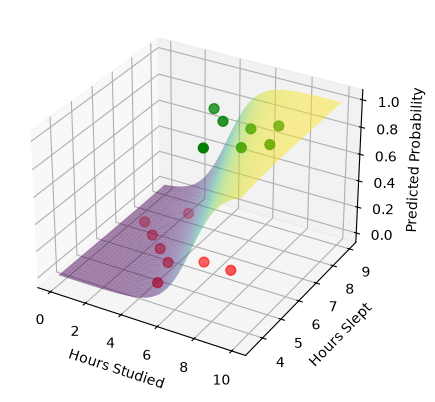

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

# Create grid of x1, x2 values
x1_range = np.linspace(min(hours_studied) - 1, max(hours_studied) + 1, 50)
x2_range = np.linspace(min(hours_slept) - 1, max(hours_slept) + 1, 50)
X1, X2 = np.meshgrid(x1_range, x2_range)

# Compute sigmoid surface
Z = 1 / (1 + np.exp(-(m[0]*X1 + m[1]*X2 + c)))

ax.plot_surface(X1, X2, Z, alpha=0.5, cmap='viridis')

# Overlay actual data points
colors = ['red' if y == 0 else 'green' for y in result]
ax.scatter(hours_studied, hours_slept, result, c=colors, s=50)

ax.set_xlabel('Hours Studied')
ax.set_ylabel('Hours Slept')
ax.set_zlabel('Predicted Probability')
plt.show()